In [10]:
import pandas as pd
import numpy as np
import duckdb
import matplotlib.pyplot as plt
from pathlib import Path

In [4]:
DATA_DIR = Path.cwd() / "data" / "nfl-big-data-bowl-2027"
combine_results = pd.read_parquet(DATA_DIR / "combine_results.parquet")
combine_tracking = pd.read_parquet(DATA_DIR / "combine_tracking.parquet")

#### Logic for labeling starts, plants, bends

**Start: the moment the player begins moving from a standstill.**
1. The attempt has to begin with the player basically still, under 0.5 yards per second. If the recording starts with him already moving, the real start wasn’t captured, so no start is recorded.
2. Find the first moment his speed goes from under 0.5 to over 0.5 yd/s.
3. Confirm it’s real movement and not a twitch: within the next half second he must reach at least 1.5 yd/s. If not, try the next crossing.
4. Label the side by where he goes over the next half second: left, right, forward or back.

**Plant cut: the player slows almost to a stop and leaves in a clearly different direction, like the reversals in the wave drill.**
1. Look for a moment where the player is nearly stopped: under 1.5 yd/s, and his slowest point within the surrounding 0.2 seconds. That’s the plant.
2. Ignore moments in the first or last half second of the attempt, because there isn’t enough data on either side to judge the direction change.
3. Compare the direction he was traveling in the half second before with the direction he travels in the half second after. Each is an average that gives more weight to frames where he’s moving faster, so the near-stop frames, where direction is unreliable, barely count.
4. If those directions differ by more than 60°, it’s a plant cut. A smaller change means he only slowed down, not cut.
5. Plants must be at least half a second apart, so one plant can’t be counted twice.
6. Label the side by the exit direction: L or R if he leaves mostly sideways, F or B if he leaves mostly forward or backward. F and B are kept but aren’t used for left/right bias.

**Bend: the player turns while still running, without stopping, like curving around the bag in the pass-rush drill or the loops in the hoop drill.**
1. For each frame, measure how fast his direction is changing (turn rate).
2. A frame counts as “turning” if he’s moving at more than 2.5 yd/s and his direction is changing at more than 30° per second. Each turning frame is marked as a left or right turn.
3. Join turning frames in the same direction into one continuous stretch:
   - Short gaps of up to 0.2 seconds are allowed, so a brief straight moment in the middle of a curve doesn’t split it in two.
   - The stretch ends when he turns the other way or stops turning for longer than that.
4. Keep the stretch as a bend only if:
   - it turned at least 45° in total, and
   - it lasted at least 0.4 seconds.
This removes small wiggles and brief changes of course.
5. Label the side by which way he was turning, left or right. This doesn’t depend on which way he’s facing, so it’s the most reliable side label.
6. Record the total turn angle.

*event_bend vs in_bend*
- event_bend is marked on one frame only, the first frame of each bend, so counting it gives the number of bends.
- in_bend is marked on every frame inside the bend, from first to last. Use it to measure what happens during the bend, such as how much speed he keeps through the curve.

In [7]:
EVENT_GROUP_COLUMNS = ["draft_year", "event_id", "nfl_id", "drill_name", "attempt"]
FRAME_SECONDS = 0.1
EVENT_WINDOW_SECONDS = 0.5

START_REST_SPEED = 0.5
START_CONFIRM_SPEED = 1.5

PLANT_MAX_SPEED = 1.5
PLANT_MIN_TURN_DEGREES = 60
PLANT_MIN_SEPARATION_SECONDS = 0.5

BEND_MIN_SPEED = 2.5
BEND_MIN_YAW_RATE = 30
BEND_MAX_GAP_SECONDS = 0.2
BEND_MIN_TURN_DEGREES = 45
BEND_MIN_DURATION_SECONDS = 0.4


def wrap_degrees(angle):
    return (angle + 180) % 360 - 180


def mean_heading(heading, speed):
    # Speed-weighted circular mean of `dir` (0 = +y, clockwise).
    radians = np.radians(heading)
    return np.degrees(np.arctan2((speed * np.sin(radians)).sum(), (speed * np.cos(radians)).sum()))


def travel_side(heading):
    # Player faces +x, so +y (dir near 0) is his left. Mostly-forward/back travel is F/B, not L/R.
    lateral = np.cos(np.radians(heading))
    if lateral > np.sqrt(0.5):
        return "L"
    if lateral < -np.sqrt(0.5):
        return "R"
    return "F" if np.sin(np.radians(heading)) > 0 else "B"


def label_attempt_events(attempt):
    attempt = attempt.sort_values("time")
    speed = pd.to_numeric(attempt["s"], errors="coerce").to_numpy()
    heading = pd.to_numeric(attempt["dir"], errors="coerce").to_numpy()
    window = int(round(EVENT_WINDOW_SECONDS / FRAME_SECONDS))
    n = len(attempt)

    event_start = np.zeros(n, dtype=bool)
    event_plant_cut = np.zeros(n, dtype=bool)
    event_bend = np.zeros(n, dtype=bool)          # flagged on the first frame of each bend
    in_bend = np.zeros(n, dtype=bool)             # every frame inside a bend
    event_side = np.full(n, None, dtype=object)   # L / R / F / B on the flagged frame
    event_turn_degrees = np.full(n, np.nan)       # signed: + = right (clockwise)

    # Start: the clip begins at rest and the player reaches START_CONFIRM_SPEED within the window.
    # Clips that begin mid-movement have no observable start.
    if n > window and speed[0] < START_REST_SPEED:
        rising = np.flatnonzero((speed[:-1] < START_REST_SPEED) & (speed[1:] >= START_REST_SPEED)) + 1
        for index in rising:
            if np.nanmax(speed[index:index + window + 1]) >= START_CONFIRM_SPEED:
                after = slice(index, min(index + window + 1, n))
                event_start[index] = True
                event_side[index] = travel_side(mean_heading(heading[after], speed[after]))
                break

    # Plant cut: speed minimum below PLANT_MAX_SPEED with a > 60 deg change between the
    # speed-weighted mean headings over the 0.5 s before and after; at least 0.5 s apart.
    last_plant = -np.inf
    for index in range(window, n - window):
        if not (speed[index] < PLANT_MAX_SPEED
                and speed[index] == np.nanmin(speed[index - 2:index + 3])
                and (index - last_plant) * FRAME_SECONDS >= PLANT_MIN_SEPARATION_SECONDS):
            continue
        before = slice(index - window, index - 1)
        after = slice(index + 2, index + window + 1)
        exit_heading = mean_heading(heading[after], speed[after])
        turn = wrap_degrees(exit_heading - mean_heading(heading[before], speed[before]))
        if abs(turn) <= PLANT_MIN_TURN_DEGREES:
            continue
        last_plant = index
        event_plant_cut[index] = True
        event_side[index] = travel_side(exit_heading)
        event_turn_degrees[index] = turn

    # Bend: a continuous same-direction turn while running (gaps up to 0.2 s allowed),
    # totalling >= 45 deg over >= 0.4 s. `dir` increases clockwise, so + yaw = right turn.
    yaw_rate = np.append(wrap_degrees(np.diff(heading)), 0) / FRAME_SECONDS
    turning = (speed > BEND_MIN_SPEED) & (np.abs(yaw_rate) > BEND_MIN_YAW_RATE)
    direction = np.where(turning, np.sign(yaw_rate), 0)
    max_gap = int(round(BEND_MAX_GAP_SECONDS / FRAME_SECONDS))
    index = 0
    while index < n:
        if direction[index] == 0:
            index += 1
            continue
        sign, start, end, gap = direction[index], index, index, 0
        cursor = index + 1
        while cursor < n and gap <= max_gap:
            if direction[cursor] == sign:
                end, gap = cursor, 0
            elif direction[cursor] == -sign:
                break
            else:
                gap += 1
            cursor += 1
        total_turn = yaw_rate[start:end + 1].sum() * FRAME_SECONDS
        duration = (end - start + 1) * FRAME_SECONDS
        if abs(total_turn) >= BEND_MIN_TURN_DEGREES and duration >= BEND_MIN_DURATION_SECONDS:
            event_bend[start] = True
            in_bend[start:end + 1] = True
            event_side[start] = "R" if sign > 0 else "L"
            event_turn_degrees[start] = total_turn
        index = end + 1

    attempt = attempt.copy()
    attempt["event_start"] = event_start
    attempt["event_plant_cut"] = event_plant_cut
    attempt["event_bend"] = event_bend
    attempt["in_bend"] = in_bend
    attempt["event_side"] = event_side
    attempt["event_turn_degrees"] = event_turn_degrees
    return attempt

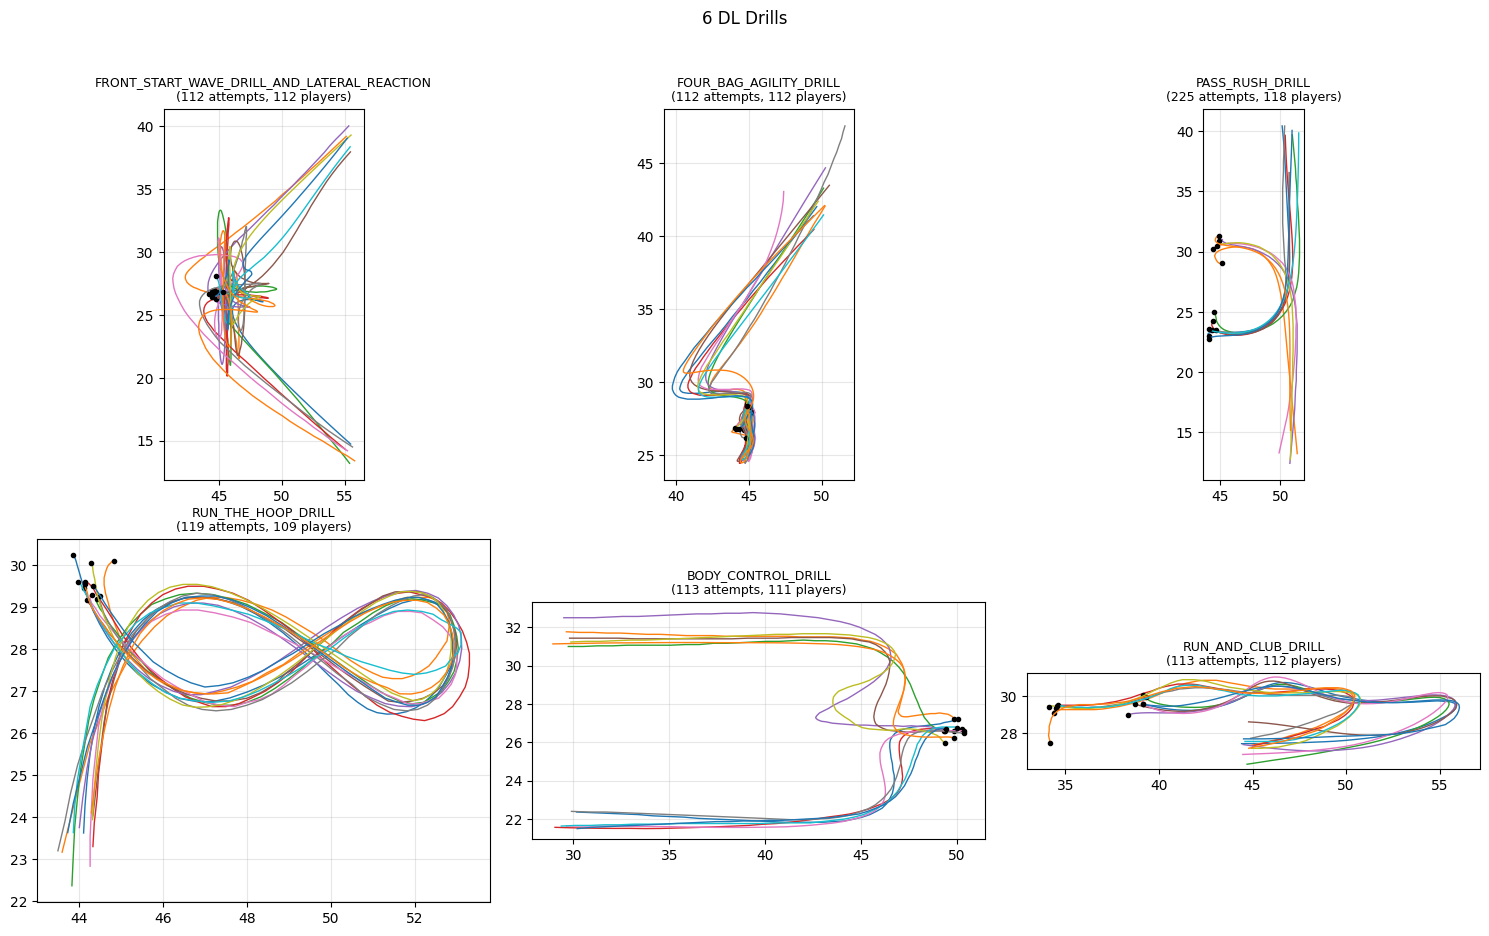

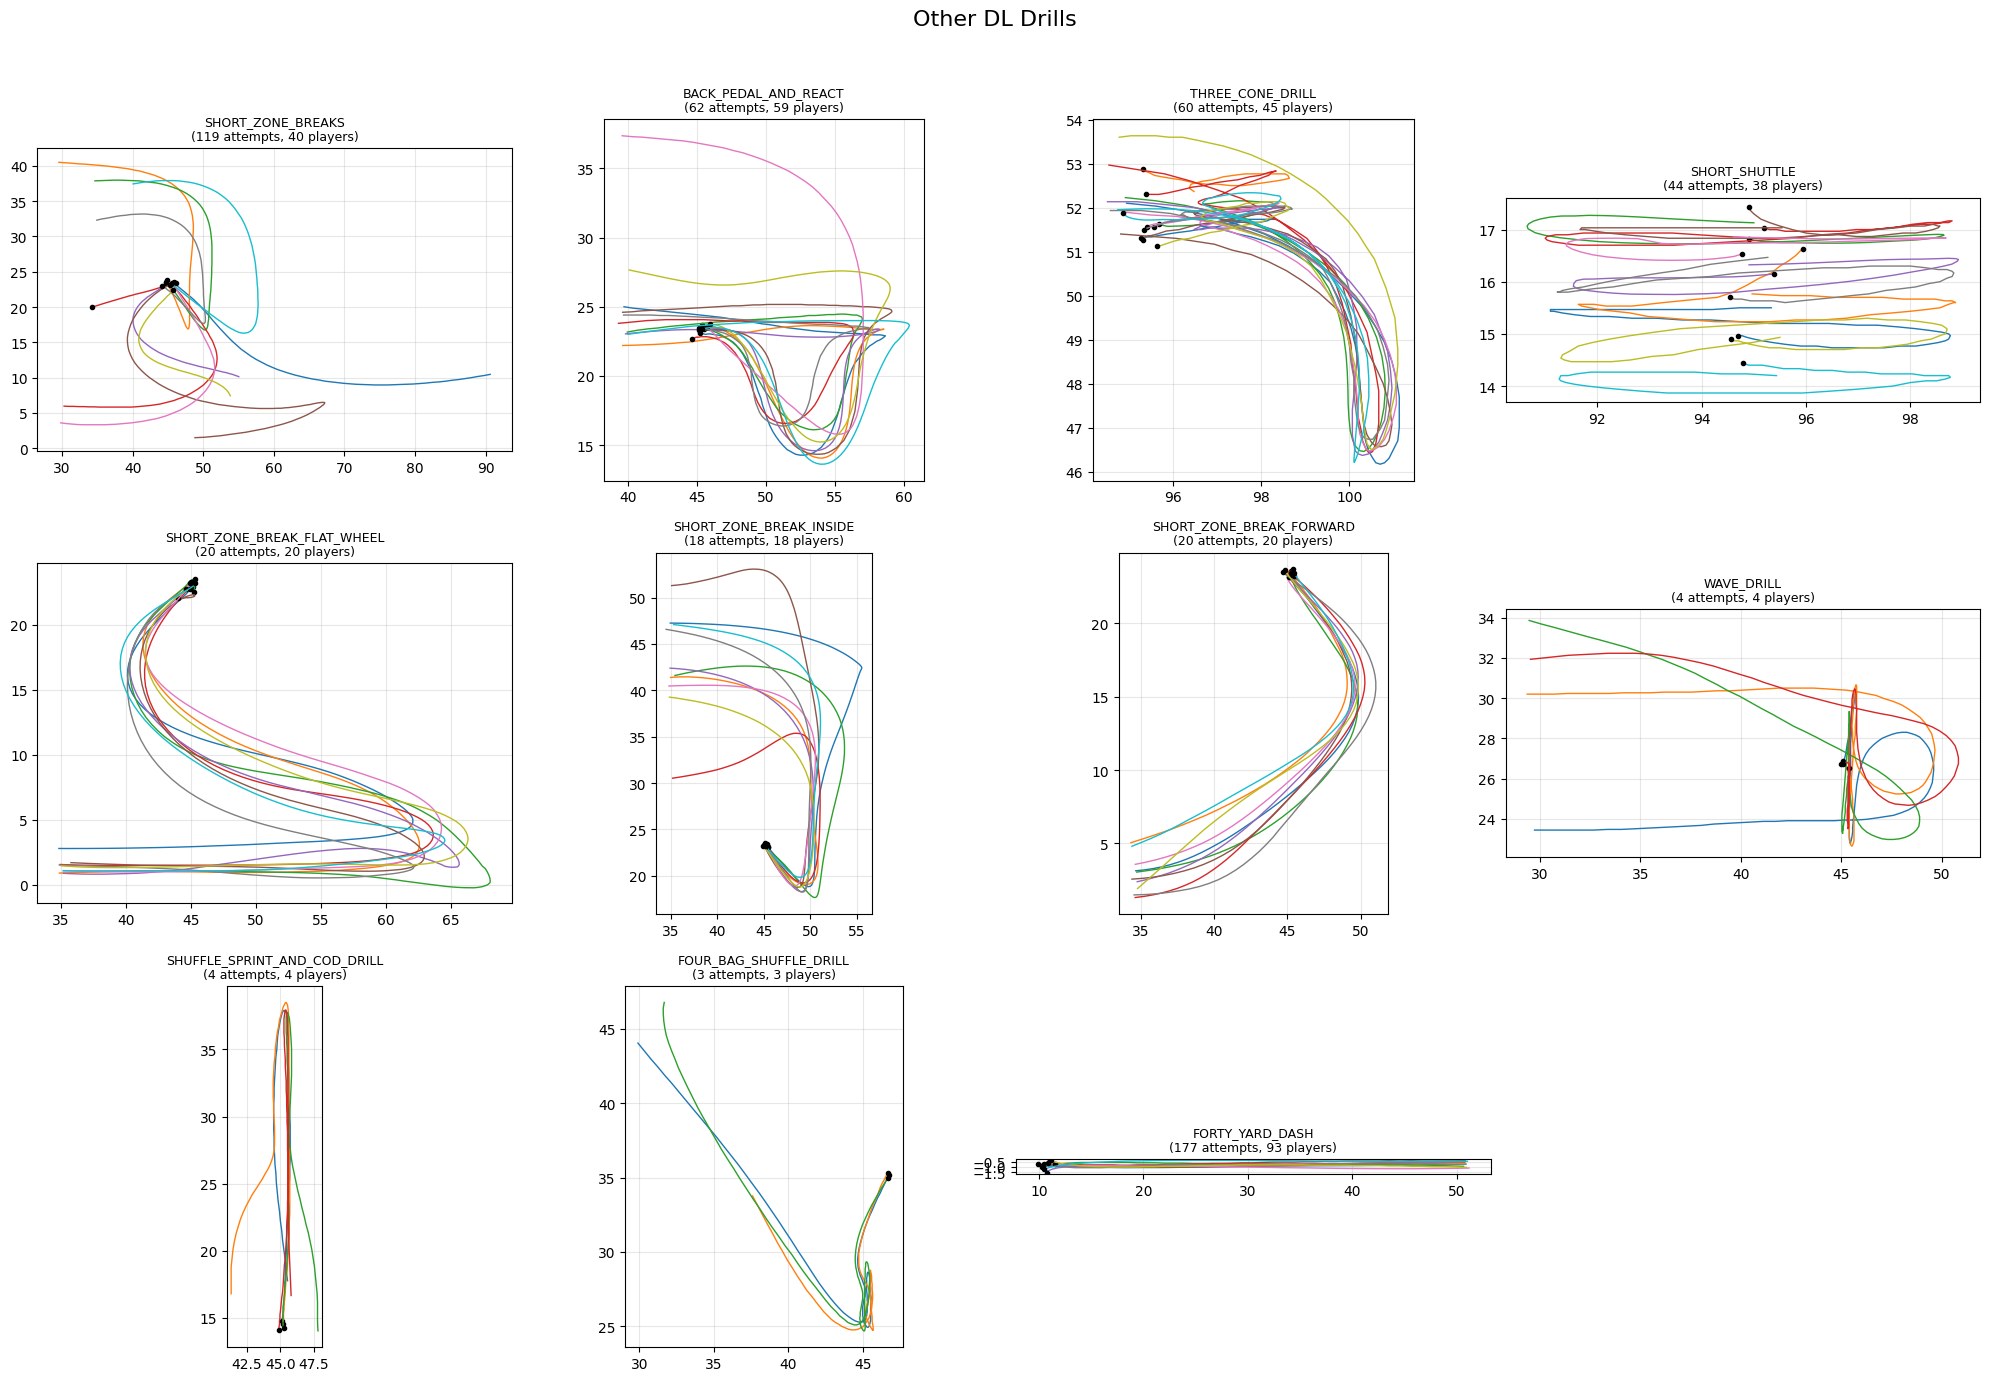

In [24]:
## Plot drill paths for DL players, and example labeled attempt with events marked to decide which drills are relevant to explosive and cutting movements

EVENT_GROUP_COLUMNS = ["draft_year", "event_id", "nfl_id", "drill_name", "attempt"]

dl_ids = set(combine_results.loc[combine_results["combine_position"] == "DL", "nfl_id"])
dl_tracking = (
    combine_tracking[combine_tracking["nfl_id"].isin(dl_ids) & (combine_tracking["entity_type"] == "PLAYER")]
    .sort_values(EVENT_GROUP_COLUMNS + ["time"])
)


def plot_drill_paths(tracking, drills, attempts_per_drill=12, columns=3, seed=0):
    """Overlay the x/y path of a random sample of attempts for each drill. Black dot = start."""
    rng = np.random.default_rng(seed)
    rows = int(np.ceil(len(drills) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(5 * columns, 4.5 * rows), squeeze=False)
    for ax, drill in zip(axes.flat, drills):
        attempts = tracking[tracking["drill_name"] == drill].groupby(EVENT_GROUP_COLUMNS)
        keys = list(attempts.groups)
        for key_index in rng.choice(len(keys), min(attempts_per_drill, len(keys)), replace=False):
            path = attempts.get_group(keys[key_index])
            ax.plot(path["x"], path["y"], lw=1)
            ax.plot(path["x"].iloc[0], path["y"].iloc[0], "ko", ms=3)
        ax.set_title(f"{drill}\n({len(keys)} attempts, {tracking.loc[tracking.drill_name == drill, 'nfl_id'].nunique()} players)",
                     fontsize=9)
        ax.set_aspect("equal")
        ax.grid(alpha=0.3)
    for ax in axes.flat[len(drills):]:
        ax.axis("off")
    fig.tight_layout()
    return fig


def plot_attempt_events(attempt):
    """Path and speed for one labeled attempt, with starts, plant cuts and bends marked.

    `attempt` must already have the columns added by label_attempt_events.
    """
    attempt = attempt.sort_values("time")
    seconds = (attempt["time"] - attempt["time"].iloc[0]).dt.total_seconds().to_numpy()
    markers = {"event_start": ("g", "start"), "event_plant_cut": ("r", "plant"), "event_bend": ("m", "bend")}

    fig, (path_ax, speed_ax) = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [1, 1.6]})
    path_ax.scatter(attempt["x"], attempt["y"], c=seconds, s=10, cmap="viridis")
    path_ax.plot(attempt.loc[attempt["in_bend"], "x"], attempt.loc[attempt["in_bend"], "y"],
                 "m.", ms=4, alpha=0.5, label="in_bend")
    speed_ax.plot(seconds, attempt["s"], label="speed (yd/s)")
    speed_ax.fill_between(seconds, 0, attempt["s"].max(), where=attempt["in_bend"].to_numpy(),
                          color="m", alpha=0.1, label="in_bend")

    for column, (color, name) in markers.items():
        flagged = attempt[column].to_numpy()
        for row, t in zip(attempt[flagged].itertuples(), seconds[flagged]):
            label = f"{name} {row.event_side}"
            path_ax.annotate(label, (row.x, row.y), color=color, fontsize=9, fontweight="bold")
            speed_ax.axvline(t, color=color, ls="--", lw=1)
            speed_ax.text(t, attempt["s"].max(), label, color=color, fontsize=8, rotation=90, va="top")

    first = attempt.iloc[0]
    path_ax.set_title(f"{first['drill_name']}\nnfl_id {first['nfl_id']}, attempt {first['attempt']} (color = time)",
                      fontsize=9)
    path_ax.set_xlabel("x (player faces +x, so +y is his left)")
    path_ax.set_ylabel("y")
    path_ax.set_aspect("equal")
    speed_ax.set_xlabel("time (s)")
    speed_ax.set_title("Speed with detected events")
    speed_ax.legend(loc="upper left", fontsize=8)
    fig.tight_layout()
    return fig


# 1. The six main DL drills
main_drills = [
    "FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION", "FOUR_BAG_AGILITY_DRILL", "PASS_RUSH_DRILL",
    "RUN_THE_HOOP_DRILL", "BODY_CONTROL_DRILL", "RUN_AND_CLUB_DRILL",
]
plot_drill_paths(dl_tracking, main_drills, attempts_per_drill=12, seed=0)
plt.suptitle("6 DL Drills", fontsize=12, y=1.02)
plt.tight_layout(rect=[0, 0, 1, 1])  
plt.show()

# 2. Every other drill DL players ran
other_drills = [
    "SHORT_ZONE_BREAKS", "BACK_PEDAL_AND_REACT", "THREE_CONE_DRILL", "SHORT_SHUTTLE",
    "SHORT_ZONE_BREAK_FLAT_WHEEL", "SHORT_ZONE_BREAK_INSIDE", "SHORT_ZONE_BREAK_FORWARD",
    "WAVE_DRILL", "SHUFFLE_SPRINT_AND_COD_DRILL", "FOUR_BAG_SHUFFLE_DRILL", "FORTY_YARD_DASH",
]
plot_drill_paths(dl_tracking, other_drills, attempts_per_drill=10, columns=4, seed=1)
plt.suptitle("Other DL Drills", fontsize=16, y=1.02)
plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()


**Front Start Wave Drill and Lateral Reaction, Pass Rush Drill, Run the Hoop Drill, Body Control Drill, and Four Bag Drill chosen as most relevant and sufficient volume.**

The labeled DL player-tracking dataframe is saved to `outputs/dl_tracking_labeled.parquet` after event labels are added. Run this notebook before `metric_summary.ipynb`.

In [6]:
## filter for DL drills that are deemed relevant to explosive and cutting movements 
dl_tracking = duckdb.query("""
SELECT 
    r.combine_position,
    t.* 
FROM combine_tracking t
LEFT JOIN combine_results r
ON t.nfl_id = r.nfl_id
WHERE combine_position ='DL'
AND entity_type = 'PLAYER'
AND drill_name IN ('FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION','PASS_RUSH_DRILL','RUN_THE_HOOP_DRILL','BODY_CONTROL_DRILL','FOUR_BAG_AGILITY_DRILL')
""").df()

In [8]:
EVENT_COLUMNS = ["event_start", "event_plant_cut", "event_bend", "in_bend", "event_side", "event_turn_degrees"]

dl_tracking[["event_start", "event_plant_cut", "event_bend", "in_bend"]] = False
dl_tracking["event_side"] = None
dl_tracking["event_turn_degrees"] = np.nan
for _, attempt in dl_tracking.groupby(EVENT_GROUP_COLUMNS, sort=False):
    if attempt["entity_type"].iloc[0] != "PLAYER":
        continue
    labeled_attempt = label_attempt_events(attempt)
    dl_tracking.loc[labeled_attempt.index, EVENT_COLUMNS] = labeled_attempt[EVENT_COLUMNS]

OUTPUT_DIR = Path.cwd() / "outputs"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
LABELED_TRACKING_PATH = OUTPUT_DIR / "dl_tracking_labeled.parquet"
dl_tracking.to_parquet(LABELED_TRACKING_PATH, index=False)
print(f"Saved {len(dl_tracking):,} labeled tracking rows to {LABELED_TRACKING_PATH}.")

In [ ]:
## labeling results: event counts and drill x event type x side
cols = ["event_start", "event_plant_cut", "event_bend"]
events = (
    dl_tracking[dl_tracking[cols].any(axis=1)]
    .melt(id_vars=["drill_name", "event_side"], value_vars=cols, var_name="event_type", value_name="flag")
    .query("flag")
)

# Totals by event type: start 411 / plant 735 / bend 852
display(events["event_type"].value_counts().to_frame("events"))

# Drill x event type x side (L / R / F / B), with row and column totals
display(pd.crosstab([events["drill_name"], events["event_type"]], events["event_side"],
                    margins=True, margins_name="Total"))

,events
event_type,
event_bend,852
event_plant_cut,735
event_start,411


event_side                                                     B    F    L  \
drill_name                                  event_type                       
BODY_CONTROL_DRILL                          event_bend         0    0   52   
                                            event_plant_cut    3   18   19   
                                            event_start       32    0    0   
FOUR_BAG_AGILITY_DRILL                      event_bend         0    0    1   
                                            event_plant_cut   99    8  154   
                                            event_start        0    0   24   
FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION event_bend         0    0   78   
                                            event_plant_cut  104    6  121   
                                            event_start        0    9   33   
PASS_RUSH_DRILL                             event_bend         0    0  111   
                                            event_plant_cut    2    7    1   
                                            event_start        0  100    2   
RUN_THE_HOOP_DRILL                          event_bend         0    0  238   
                                            event_plant_cut    3    0    0   
                                            event_start        0    6    0   
Total                                                        243  154  834   

event_side                                                     R  Total  
drill_name                                  event_type                   
BODY_CONTROL_DRILL                          event_bend        40     92  
                                            event_plant_cut    5     45  
                                            event_start        0     32  
FOUR_BAG_AGILITY_DRILL                      event_bend        12     13  
                                            event_plant_cut   67    328  
                                            event_start       41     65  
FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION event_bend        53    131  
                                            event_plant_cut  114    345  
                                            event_start       47     89  
PASS_RUSH_DRILL                             event_bend       114    225  
                                            event_plant_cut    3     13  
                                            event_start       12    114  
RUN_THE_HOOP_DRILL                          event_bend       153    391  
                                            event_plant_cut    1      4  
                                            event_start      105    111  
Total                                                        767   1998